In [43]:
!zip -r unetpp_aspect10_mod_2_outputs.zip /content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs

  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/ (stored 0%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/validation_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/test_metrics_per_image.png (deflated 17%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/test_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/dataset_split_manifest.csv (deflated 91%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/test_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/test_metrics_per_image.csv (deflated 42%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/validation_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod2_fixedkernel_outputs/validation_metrics_p

In [44]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split
from google.colab import drive


IMG_SIZE = (256, 256)
BATCH_SIZE = 1
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
IMAGE_DIR = "/content/ASPECT-10/ASPECT-10/IMAGES"
MASK_DIR = "/content/ASPECT-10/ASPECT-10/Binary_Mask"
OUTPUT_DIR = '/content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs'
MODEL_LABEL = 'U-Net++ Modification 3 — Learnable Kernels'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory in (IMAGE_DIR, MASK_DIR):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Required dataset directory not found: {directory}")

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU detected. Select Runtime > Change runtime type > GPU in Colab.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)
print("Output directory:", OUTPUT_DIR)


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Image directory: /content/ASPECT-10/ASPECT-10/IMAGES
Mask directory: /content/ASPECT-10/ASPECT-10/Binary_Mask
Output directory: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs


In [45]:
def get_pairs(image_dir, mask_dir):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    image_files = sorted(
        os.path.join(image_dir, name)
        for name in os.listdir(image_dir)
        if os.path.isfile(os.path.join(image_dir, name)) and os.path.splitext(name)[1].lower() in valid_exts
    )
    mask_files = sorted(
        os.path.join(mask_dir, name)
        for name in os.listdir(mask_dir)
        if os.path.isfile(os.path.join(mask_dir, name)) and os.path.splitext(name)[1].lower() in valid_exts
    )
    image_map = {}
    mask_map = {}
    for path in image_files:
        stem = os.path.splitext(os.path.basename(path))[0]
        if stem in image_map:
            raise ValueError(f"Duplicate image filename stem: {stem}")
        image_map[stem] = path
    for path in mask_files:
        stem = os.path.splitext(os.path.basename(path))[0]
        if stem in mask_map:
            raise ValueError(f"Duplicate mask filename stem: {stem}")
        mask_map[stem] = path
    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))
    if missing_masks or missing_images:
        raise ValueError(f"Image/mask pairing mismatch. Images without masks: {missing_masks}; masks without images: {missing_images}")
    return [(image_map[stem], mask_map[stem]) for stem in sorted(image_map)]

pairs = get_pairs(IMAGE_DIR, MASK_DIR)
if len(pairs) < 10:
    raise ValueError(f"At least 10 paired image-mask samples are required for train/validation/test splitting; found {len(pairs)}.")

train_pairs, holdout_pairs = train_test_split(pairs, test_size=0.2, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(holdout_pairs, test_size=0.5, random_state=SEED, shuffle=True)

split_lists = {"train": train_pairs, "validation": val_pairs, "test": test_pairs}
split_stems = {
    name: [os.path.splitext(os.path.basename(image_path))[0] for image_path, _ in split]
    for name, split in split_lists.items()
}
all_stems = [stem for stems in split_stems.values() for stem in stems]
if len(all_stems) != len(pairs) or len(set(all_stems)) != len(pairs):
    raise RuntimeError("Split integrity check failed: one or more samples were lost or assigned more than once.")
if not set(split_stems["train"]).isdisjoint(split_stems["validation"]):
    raise RuntimeError("Train/validation overlap detected.")
if not set(split_stems["train"]).isdisjoint(split_stems["test"]):
    raise RuntimeError("Train/test overlap detected.")
if not set(split_stems["validation"]).isdisjoint(split_stems["test"]):
    raise RuntimeError("Validation/test overlap detected.")

manifest_rows = [
    {"split": split_name, "image": image_path, "mask": mask_path, "sample_id": os.path.splitext(os.path.basename(image_path))[0]}
    for split_name, split in split_lists.items()
    for image_path, mask_path in split
]
manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)


def load_image_mask(img_path, mask_path):
    if isinstance(img_path, (bytes, np.bytes_)):
        img_path = img_path.decode("utf-8")
    if isinstance(mask_path, (bytes, np.bytes_)):
        mask_path = mask_path.decode("utf-8")
    image = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)[..., np.newaxis]
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(load_image_mask, [img_path, mask_path], [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def duplicate_mask(image, mask):
    return image, (mask, mask, mask, mask)


def make_dataset(split_pairs, training=False, duplicate=False):
    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(len(split_pairs), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if duplicate:
        dataset = dataset.map(duplicate_mask, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds_multi = make_dataset(train_pairs, training=True, duplicate=True)
val_ds_multi = make_dataset(val_pairs, duplicate=True)
val_ds_single = make_dataset(val_pairs)

print("Total paired samples:", len(pairs))
print("Train:", len(train_pairs), "Validation:", len(val_pairs), "Test:", len(test_pairs))
print("Split manifest:", manifest_path)


Total paired samples: 30
Train: 24 Validation: 3 Test: 3
Split manifest: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/dataset_split_manifest.csv


Model: "UNetPlusPlus_Modified3_LearnableKernel_Train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_218 (Conv2D) │ (None, 256, 256,  │        896 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_215 (ReLU)    │ (None, 256, 256,  │          0 │ conv2d_218[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_219 (Conv2D) │ (None, 256, 256,  │      9,248 │ re_lu_215[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_216 (ReLU)    │ (None, 256, 256,  │          0 │ conv2d_219[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_32    │ (None, 128, 128,  │          0 │ re_lu_216[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_220 (Conv2D) │ (None, 128, 128,  │     18,496 │ max_pooling2d_32… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_217 (ReLU)    │ (None, 128, 128,  │          0 │ conv2d_220[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_221 (Conv2D) │ (None, 128, 128,  │     36,928 │ re_lu_217[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_218 (ReLU)    │ (None, 128, 128,  │          0 │ conv2d_221[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_33    │ (None, 64, 64,    │          0 │ re_lu_218[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_222 (Conv2D) │ (None, 64, 64,    │     73,856 │ max_pooling2d_33… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_219 (ReLU)    │ (None, 64, 64,    │          0 │ conv2d_222[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_223 (Conv2D) │ (None, 64, 64,    │    147,584 │ re_lu_219[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_220 (ReLU)    │ (None, 64, 64,    │          0 │ conv2d_223[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_34    │ (None, 32, 32,    │          0 │ re_lu_220[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_224 (Conv2D) │ (None, 32, 32,    │    295,168 │ max_pooling2d_34

 Total params: 8,813,092 (33.62 MB)

 Trainable params: 8,813,092 (33.62 MB)

 Non-trainable params: 0 (0.00 B)

Model: "UNetPlusPlus_Modified3_LearnableKernel_Infer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_218 (Conv2D) │ (None, 256, 256,  │        896 │ input_layer_8[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_215 (ReLU)    │ (None, 256, 256,  │          0 │ conv2d_218[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_219 (Conv2D) │ (None, 256, 256,  │      9,248 │ re_lu_215[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_216 (ReLU)    │ (None, 256, 256,  │          0 │ conv2d_219[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_32    │ (None, 128, 128,  │          0 │ re_lu_216[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_220 (Conv2D) │ (None, 128, 128,  │     18,496 │ max_pooling2d_32… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_217 (ReLU)    │ (None, 128, 128,  │          0 │ conv2d_220[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_221 (Conv2D) │ (None, 128, 128,  │     36,928 │ re_lu_217[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_218 (ReLU)    │ (None, 128, 128,  │          0 │ conv2d_221[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_33    │ (None, 64, 64,    │          0 │ re_lu_218[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_222 (Conv2D) │ (None, 64, 64,    │     73,856 │ max_pooling2d_33… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_219 (ReLU)    │ (None, 64, 64,    │          0 │ conv2d_222[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_223 (Conv2D) │ (None, 64, 64,    │    147,584 │ re_lu_219[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_220 (ReLU)    │ (None, 64, 64,    │          0 │ conv2d_223[0][0]  │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_34    │ (None, 32, 32,    │          0 │ re_lu_220[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_224 (Conv2D) │ (None, 32, 32,    │    295,168 │ max_pooling2d_34

 Total params: 8,813,092 (33.62 MB)

 Trainable params: 8,813,092 (33.62 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step - loss: 0.3478 - side_1_accuracy: 0.7444 - side_1_dice_coef: 0.7893 - side_1_iou_coef: 0.6687 - side_1_loss: 0.4409 - side_2_accuracy: 0.8007 - side_2_dice_coef: 0.8384 - side_2_iou_coef: 0.7378 - side_2_loss: 0.3634 - side_3_accuracy: 0.9094 - side_3_dice_coef: 0.9220 - side_3_iou_coef: 0.8592 - side_3_loss: 0.2411 - side_4_accuracy: 0.8408 - side_4_dice_coef: 0.8934 - side_4_iou_coef: 0.8229 - side_4_loss: 0.3459
val_avg_loss=0.1314 val_avg_dice_coef=0.9504 val_avg_iou_coef=0.9058
Saved best inference weights: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/best_inference.weights.h5
24/24 ━━━━━━━━━━━━━━━━━━━━ 37s 467ms/step - loss: 0.2418 - side_1_accuracy: 0.8718 - side_1_dice_coef: 0.8794 - side_1_iou_coef: 0.7982 - side_1_loss: 0.2820 - side_2_accuracy: 0.8873 - side_2_dice_coef: 0.9089 - side_2_iou_coef: 0.8425 - side_2_loss: 0.2396 - side_3_accuracy: 0.9233 - side_3_dice_coef: 0.9415 - side_3_iou_coef: 0.891

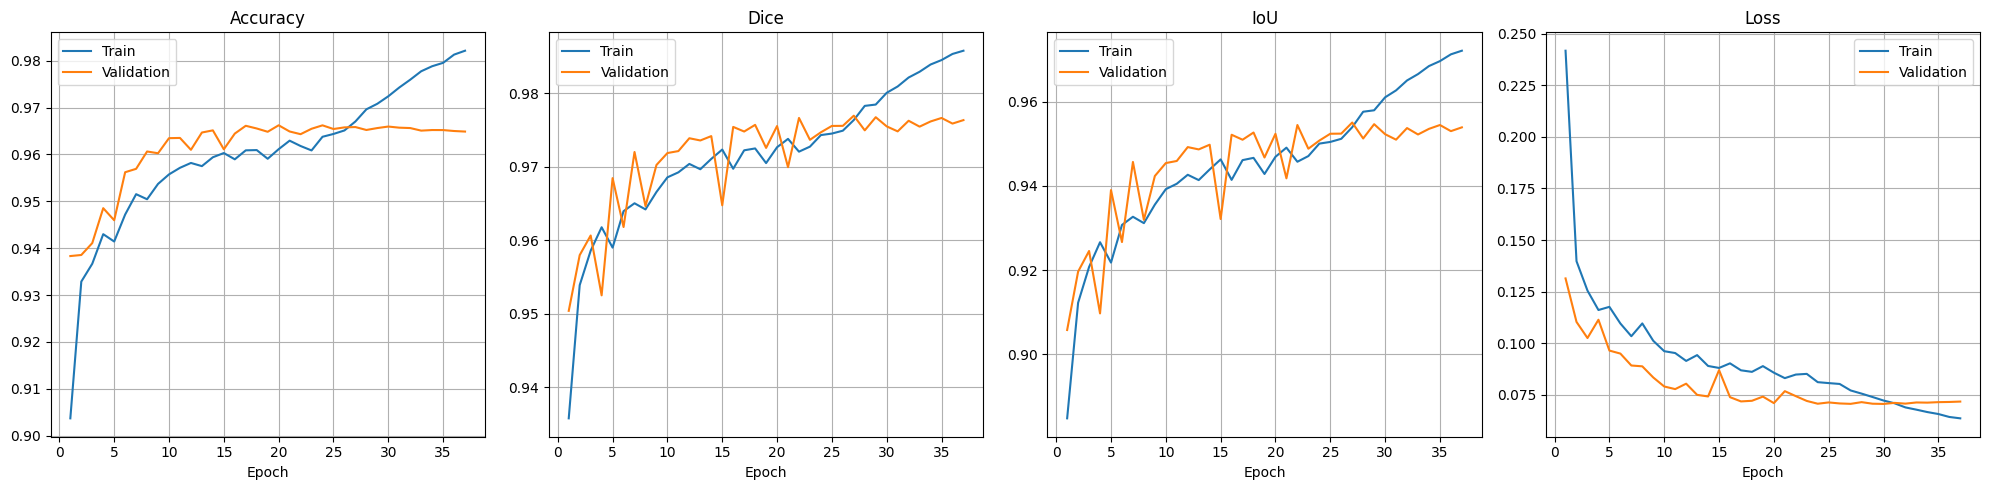

Best inference weights: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/best_inference.weights.h5


In [46]:
bce_loss_fn = tf.keras.losses.BinaryCrossentropy()

def dice_coef(y_true, y_pred, smooth=1e-07):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_bce_dice_loss(y_true, y_pred):
    bce = bce_loss_fn(y_true, y_pred)
    dloss = dice_loss(y_true, y_pred)
    return 0.5 * bce + dloss

def iou_coef(y_true, y_pred, smooth=1e-07):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.ReLU()(x)
    return x

@tf.keras.utils.register_keras_serializable(package='RockSegmentation')
class LearnableKernelLayer(layers.Layer):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])
        sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
        sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
        laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
        init_kernel = np.zeros((3, 3, c, 3), dtype=np.float32)
        for ch in range(c):
            init_kernel[:, :, ch, 0] = sobel_x
            init_kernel[:, :, ch, 1] = sobel_y
            init_kernel[:, :, ch, 2] = laplacian
        self.kernel = self.add_weight(name='kernel', shape=(3, 3, c, 3), initializer=tf.keras.initializers.Constant(init_kernel), trainable=True)

    def call(self, x):
        return tf.nn.depthwise_conv2d(x, self.kernel, strides=[1, 1, 1, 1], padding='SAME')

def merge_with_learnable_kernels(inputs_list, filters, prefix):
    original_feats = inputs_list
    learned_feats = []
    for idx, feat in enumerate(original_feats):
        lk = LearnableKernelLayer(name=f'{prefix}_learnable_{idx}')(feat)
        learned_feats.append(lk)
    x = layers.Concatenate(name=f'{prefix}_concat')(original_feats + learned_feats)
    x = layers.Conv2D(filters, 1, padding='same', kernel_initializer='he_normal', name=f'{prefix}_compress')(x)
    x = layers.ReLU(name=f'{prefix}_compress_relu')(x)
    return x

def build_unet_plus_plus_learnable(input_shape=(256, 256, 3)):
    filters = [32, 64, 128, 256, 512]
    depth = len(filters) - 1
    inputs = layers.Input(shape=input_shape)
    X = {}
    x = inputs
    for i in range(depth + 1):
        X[i, 0] = conv_block(x, filters[i])
        if i < depth:
            x = layers.MaxPooling2D((2, 2))(X[i, 0])
    for j in range(1, depth + 1):
        for i in range(0, depth - j + 1):
            up = layers.Conv2DTranspose(filters[i], kernel_size=2, strides=2, padding='same', name=f'up_{i}_{j}')(X[i + 1, j - 1])
            base_feats = [X[i, k] for k in range(j)] + [up]
            merged = merge_with_learnable_kernels(base_feats, filters[i], prefix=f'merge_{i}_{j}')
            X[i, j] = conv_block(merged, filters[i])
    side_outputs = [layers.Conv2D(1, 1, activation='sigmoid', name=f'side_{j}')(X[0, j]) for j in range(1, depth + 1)]
    train_model = Model(inputs, side_outputs, name='UNetPlusPlus_Modified3_LearnableKernel_Train')
    avg_output = layers.Average(name='avg_output')(side_outputs)
    infer_model = Model(inputs, avg_output, name='UNetPlusPlus_Modified3_LearnableKernel_Infer')
    return (train_model, infer_model)

train_model, infer_model = build_unet_plus_plus_learnable((IMG_SIZE[0], IMG_SIZE[1], 3))
train_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=[combined_bce_dice_loss] * 4,
    loss_weights=[0.25] * 4,
    metrics=[["accuracy", dice_coef, iou_coef] for _ in range(4)],
)
infer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=combined_bce_dice_loss,
    metrics=["accuracy", dice_coef, iou_coef],
)

BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, "best_inference.weights.h5")

def metric_value(results, name):
    if name in results:
        return results[name]
    matches = [value for key, value in results.items() if key.endswith("_" + name)]
    if matches:
        return matches[0]
    raise KeyError(f"Metric {name} was not found in evaluation results: {list(results)}")

class EvaluateAndSaveBest(tf.keras.callbacks.Callback):
    def __init__(self, inference_model, validation_dataset, checkpoint_path):
        super().__init__()
        self.inference_model = inference_model
        self.validation_dataset = validation_dataset
        self.checkpoint_path = checkpoint_path
        self.best_dice = -np.inf

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        results = self.inference_model.evaluate(self.validation_dataset, verbose=0, return_dict=True)
        for key in ("loss", "accuracy", "dice_coef", "iou_coef"):
            logs[f"val_avg_{key}"] = float(metric_value(results, key))
        current_dice = logs["val_avg_dice_coef"]
        print(f"\nval_avg_loss={logs['val_avg_loss']:.4f} val_avg_dice_coef={current_dice:.4f} val_avg_iou_coef={logs['val_avg_iou_coef']:.4f}")
        if current_dice > self.best_dice:
            self.best_dice = current_dice
            self.inference_model.save_weights(self.checkpoint_path)
            print("Saved best inference weights:", self.checkpoint_path)

best_callback = EvaluateAndSaveBest(infer_model, val_ds_single, BEST_WEIGHTS_PATH)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_avg_dice_coef", mode="max", patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_avg_dice_coef", mode="max", factor=0.5, patience=4, verbose=1
)

train_model.summary()
infer_model.summary()
history = train_model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=[best_callback, early_stopping, reduce_lr],
)
infer_model.load_weights(BEST_WEIGHTS_PATH)

hist = history.history
epoch_numbers = np.arange(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
curve_settings = [
    ("side_4_accuracy", "val_avg_accuracy", "Accuracy"),
    ("side_4_dice_coef", "val_avg_dice_coef", "Dice"),
    ("side_4_iou_coef", "val_avg_iou_coef", "IoU"),
    ("loss", "val_avg_loss", "Loss"),
]
for ax, (train_key, val_key, title) in zip(axes, curve_settings):
    if train_key in hist:
        ax.plot(epoch_numbers, hist[train_key], label="Train")
    if val_key in hist:
        ax.plot(epoch_numbers, hist[val_key], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Best inference weights:", BEST_WEIGHTS_PATH)


Validation image 1/3: Agg_Rounded_Black_M_HLC_03.jpg
Validation image 2/3: Agg_Crushed_Clear_M_GLC_03.jpg
Validation image 3/3: Agg_Crushed_Red_S_GLC_03.jpg

U-Net++ Modification 3 — Learnable Kernels — VALIDATION MACRO METRICS OVER 3 IMAGES
IoU                     : 0.9646 ± 0.0103
Recall                  : 0.9928 ± 0.0057
Precision               : 0.9713 ± 0.0056
Dice Coefficient        : 0.9819 ± 0.0053
Boundary F1             : 0.7442 ± 0.0987
Boundary Recall         : 0.6158 ± 0.1328
Boundary Precision      : 0.9636 ± 0.0285


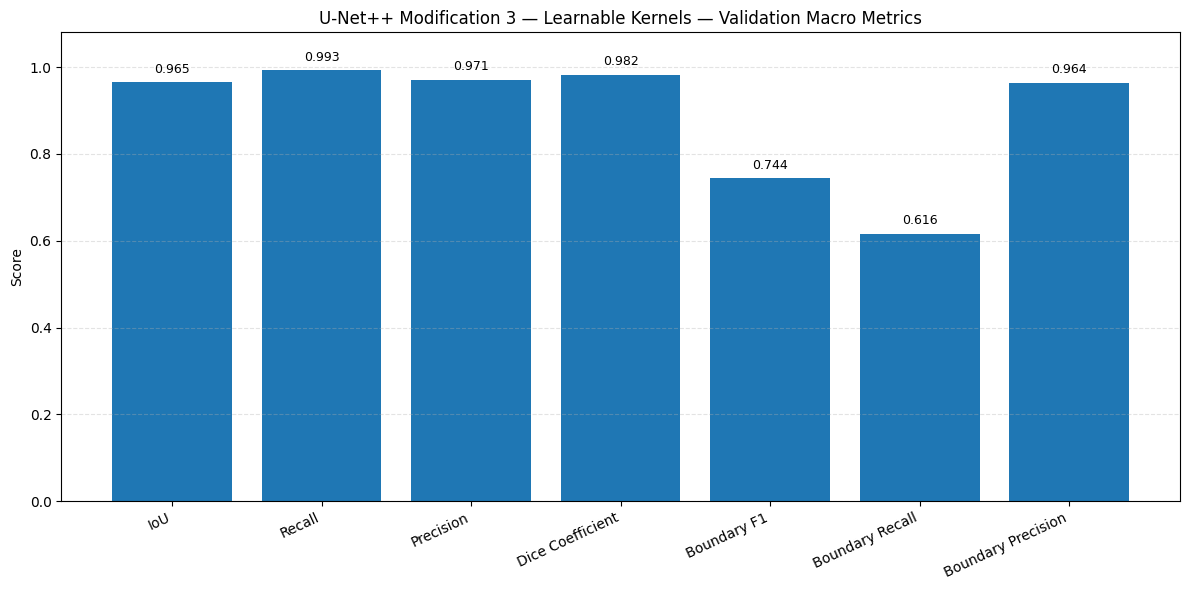

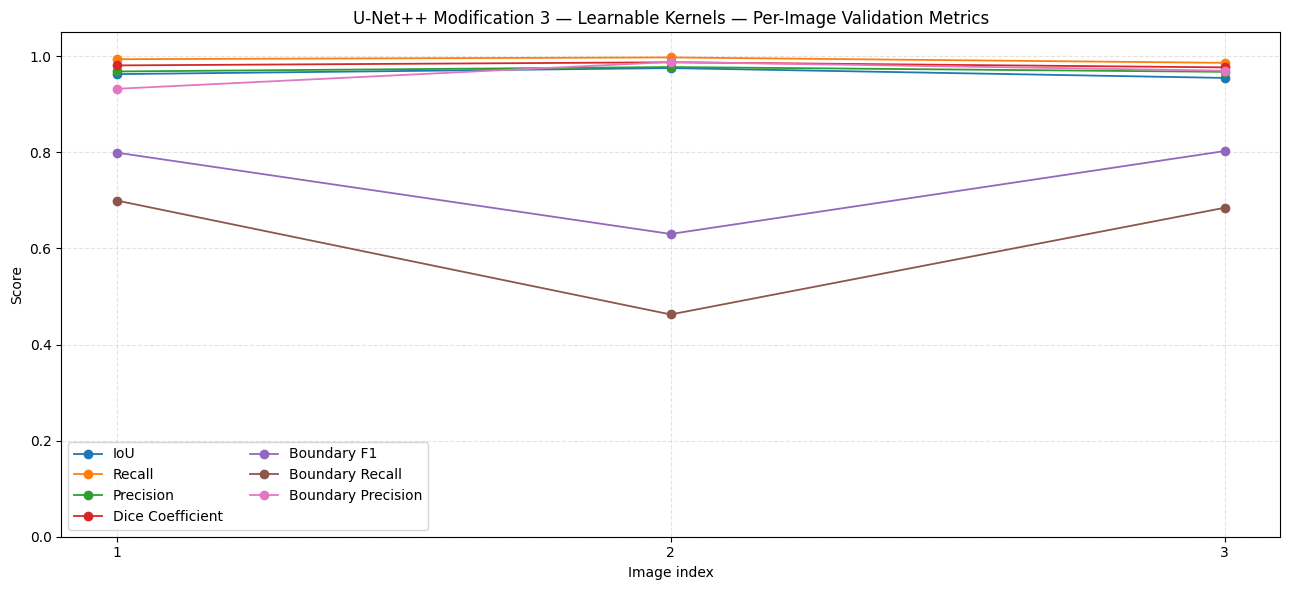

Saved metrics and plots in: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs
Test image 1/3: LightAgg_Black_M_HTC_01.jpg
Test image 2/3: Agg_Crushed_Red_S_GLC_01.jpg
Test image 3/3: Agg_Crushed_Green_M_GLC_01.jpg

U-Net++ Modification 3 — Learnable Kernels — TEST MACRO METRICS OVER 3 IMAGES
IoU                     : 0.9690 ± 0.0105
Recall                  : 0.9927 ± 0.0034
Precision               : 0.9760 ± 0.0130
Dice Coefficient        : 0.9842 ± 0.0054
Boundary F1             : 0.7964 ± 0.0786
Boundary Recall         : 0.6926 ± 0.1378
Boundary Precision      : 0.9549 ± 0.0273


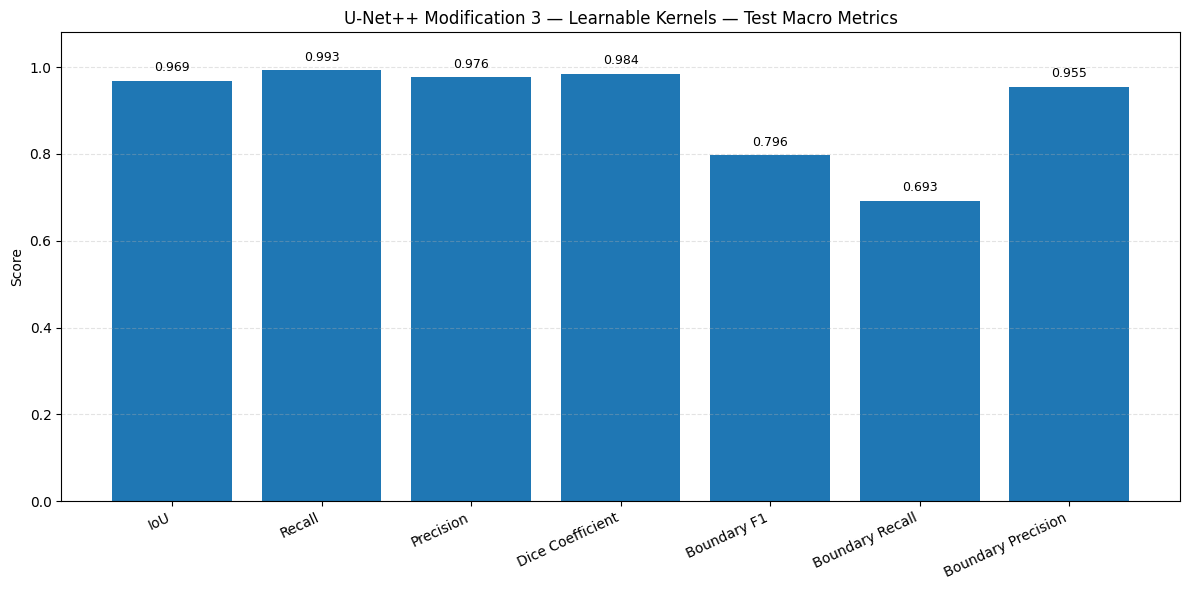

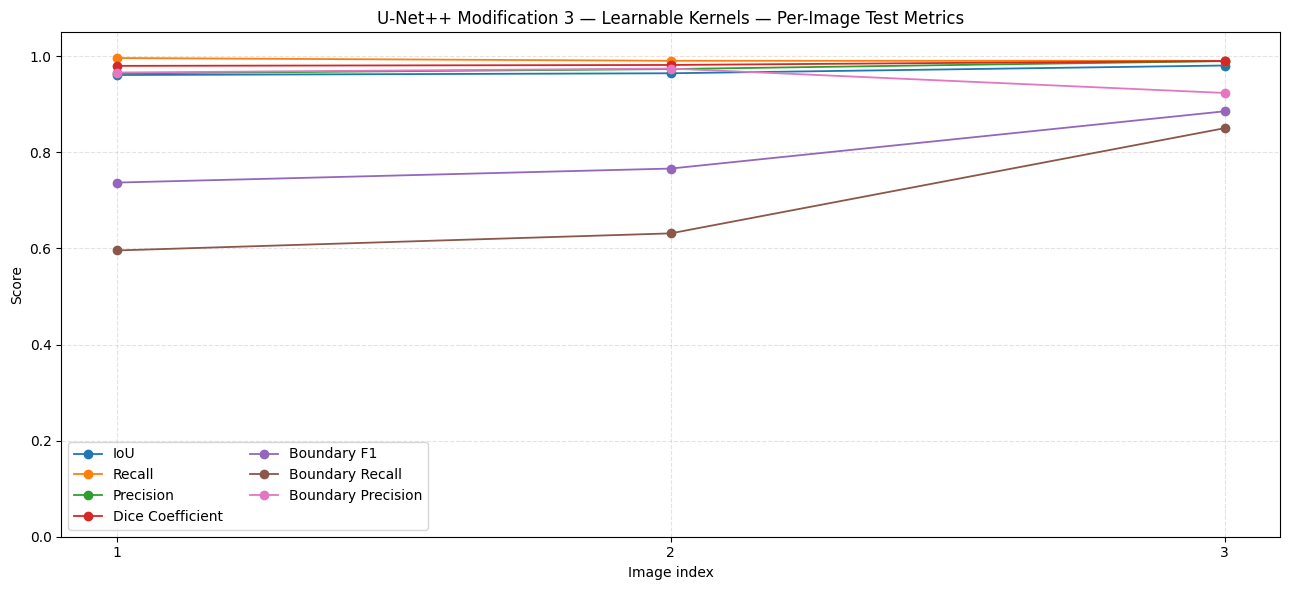

Saved metrics and plots in: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs
Saved test predicted masks in: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_predicted_masks
TEST EVALUATION COMPLETE.
Held-out test predicted masks: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_predicted_masks
Dataset split manifest: /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/dataset_split_manifest.csv


In [47]:
METRIC_NAMES = ["iou", "recall", "precision", "dice_coef", "boundary_f1", "boundary_recall", "boundary_precision"]
DISPLAY_NAMES = {
    "iou": "IoU",
    "recall": "Recall",
    "precision": "Precision",
    "dice_coef": "Dice Coefficient",
    "boundary_f1": "Boundary F1",
    "boundary_recall": "Boundary Recall",
    "boundary_precision": "Boundary Precision",
}


def extract_binary_boundary(binary_mask):
    mask = (np.asarray(binary_mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(mask, np.ones((3, 3), dtype=np.uint8), iterations=1, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return (mask - eroded).astype(np.uint8)


def segmentation_scores(gt_mask, pred_mask, tolerance=BOUNDARY_TOLERANCE):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shape mismatch: GT {gt.shape}, prediction {pred.shape}")
    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))
    precision = tp / (tp + fp) if tp + fp else (1.0 if tp + fn == 0 else 0.0)
    recall = tp / (tp + fn) if tp + fn else (1.0 if tp + fp == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn
    dice = 2 * tp / dice_den if dice_den else 1.0
    iou = tp / iou_den if iou_den else 1.0
    gt_boundary = extract_binary_boundary(gt)
    pred_boundary = extract_binary_boundary(pred)
    tolerance = max(0, int(tolerance))
    if tolerance:
        kernel_size = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)
    else:
        gt_dilated, pred_dilated = gt_boundary, pred_boundary
    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))
    pred_count = int(pred_boundary.sum())
    gt_count = int(gt_boundary.sum())
    boundary_precision = matched_pred / pred_count if pred_count else (1.0 if gt_count == 0 else 0.0)
    boundary_recall = matched_gt / gt_count if gt_count else (1.0 if pred_count == 0 else 0.0)
    boundary_sum = boundary_precision + boundary_recall
    boundary_f1 = 2 * boundary_precision * boundary_recall / boundary_sum if boundary_sum else 0.0
    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


def evaluate_split(split_pairs, split_name, save_predictions=False):
    if not split_pairs:
        raise ValueError(f"The {split_name} split is empty.")
    prediction_dir = os.path.join(OUTPUT_DIR, f"{split_name}_predicted_masks")
    if save_predictions:
        os.makedirs(prediction_dir, exist_ok=True)
    rows = []
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, true_mask = load_image_mask(image_path, mask_path)
        predicted_probability = infer_model.predict(image[np.newaxis, ...], verbose=0)[0]
        predicted_mask = (np.asarray(predicted_probability).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
        true_binary = (np.asarray(true_mask).squeeze() > 0.5).astype(np.uint8)
        scores = segmentation_scores(true_binary, predicted_mask, BOUNDARY_TOLERANCE)
        rows.append({"image": os.path.basename(image_path), **scores})
        if save_predictions:
            stem = os.path.splitext(os.path.basename(image_path))[0]
            output_path = os.path.join(prediction_dir, f"{stem}_pred.png")
            if not cv2.imwrite(output_path, predicted_mask * 255):
                raise IOError(f"Could not save predicted mask: {output_path}")
        print(f"{split_name.title()} image {index}/{len(split_pairs)}: {os.path.basename(image_path)}")
    results = pd.DataFrame(rows)
    means = results[METRIC_NAMES].mean()
    stds = results[METRIC_NAMES].std(ddof=1).fillna(0.0) if len(results) > 1 else means * 0.0
    summary = pd.DataFrame({
        "metric": [DISPLAY_NAMES[name] for name in METRIC_NAMES],
        "mean_score": [float(means[name]) for name in METRIC_NAMES],
        "std_score": [float(stds[name]) for name in METRIC_NAMES],
        "n_images": [len(results)] * len(METRIC_NAMES),
    })
    results.to_csv(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.csv"), index=False)
    summary.to_csv(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_summary.csv"), index=False)
    print("\n" + "=" * 64)
    print(f"{MODEL_LABEL} — {split_name.upper()} MACRO METRICS OVER {len(results)} IMAGES")
    for name in METRIC_NAMES:
        print(f"{DISPLAY_NAMES[name]:<24}: {means[name]:.4f} ± {stds[name]:.4f}")
    print("=" * 64)
    values = [float(means[name]) for name in METRIC_NAMES]
    labels = [DISPLAY_NAMES[name] for name in METRIC_NAMES]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, values)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title(f"{MODEL_LABEL} — {split_name.title()} Macro Metrics")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_macro_average.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.figure(figsize=(13, 6))
    image_indices = np.arange(1, len(results) + 1)
    for name in METRIC_NAMES:
        plt.plot(image_indices, results[name], marker="o", linewidth=1.3, label=DISPLAY_NAMES[name])
    plt.ylim(0, 1.05)
    plt.xlabel("Image index")
    plt.ylabel("Score")
    plt.title(f"{MODEL_LABEL} — Per-Image {split_name.title()} Metrics")
    plt.xticks(image_indices)
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.png"), dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved metrics and plots in:", OUTPUT_DIR)
    if save_predictions:
        print("Saved test predicted masks in:", prediction_dir)
    return results, summary

validation_results, validation_summary = evaluate_split(val_pairs, "validation", save_predictions=False)
test_results, test_summary = evaluate_split(test_pairs, "test", save_predictions=True)
print("TEST EVALUATION COMPLETE.")
print("Held-out test predicted masks:", os.path.join(OUTPUT_DIR, "test_predicted_masks"))
print("Dataset split manifest:", manifest_path)
